# 用 GRPO 复现 DeepSeek-R1 思维链(雏形)

> 个人学习项目 · Qwen2.5-0.5B + GRPO + gsm8k · 本地 Apple M4 Pro(MPS)跑通

## 这个项目想干嘛
让一个**很小**的模型(0.5B)通过**强化学习**学会:① 按格式输出 `<reasoning>..</reasoning><answer>..</answer>`;② 把小学数学题算对。

## SFT / DPO / GRPO 一句话区别(面试必背)
| 方法 | 给模型什么 | 教它什么 |
|---|---|---|
| **SFT** | 标准答案,让它模仿 | "**说什么**" |
| **DPO** | 好/坏两个回答的偏好对 | "**怎么选**" |
| **GRPO**(本项目) | 不给答案,只给一个 **reward 函数当裁判** | "**怎么想**" |

GRPO 做法:模型对同一题采样**一组**(G个)回答 → 裁判给每个打分 → 朝"得分高于组内平均"的回答更新。这就是 DeepSeek-R1 用 RL 逼出推理能力的核心。

> 逐格运行即可。训练格子可调 `MAX_STEPS` 控制快慢。

## 1. 环境 & 常量
首次运行会从 HuggingFace 下模型/数据(已缓存则秒开)。`PYTORCH_ENABLE_MPS_FALLBACK=1` 让苹果 GPU 不支持的算子回退 CPU,防崩。

In [13]:
# ===== 导入需要的库 =====
import os

# 环境变量:苹果 GPU(MPS)有个别运算不支持,遇到就自动改用 CPU 算,避免训练中途崩溃
# (setdefault = 如果外面没设置过这个变量,就设成 "1")
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import re      # 正则表达式库:后面裁判用它从文本里"抠"标签和数字
import json    # 读写 json 文件(保存训练日志用)
import torch   # PyTorch:深度学习框架,模型的底层计算都靠它(本项目不用手写任何 torch 代码)

from datasets import load_dataset       # HuggingFace 数据集库:一行代码下载 gsm8k
from transformers import AutoTokenizer  # 分词器:文字 <-> token 互转(模型只认 token 不认字)
from peft import LoraConfig             # LoRA 配置:只训练一小部分参数,省显存
from trl import GRPOConfig, GRPOTrainer # trl 库:GRPO 算法的现成实现,核心训练逻辑都在里面

# 用哪个模型:Qwen2.5 的 0.5B 参数指令版(很小,笔记本跑得动)
# 这是 HuggingFace 上的模型名,首次运行自动下载(约 1GB),之后走本地缓存
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

# 打印 PyTorch 版本 + 苹果 GPU 是否可用(True 才能用 GPU 加速)
print("torch", torch.__version__, "| MPS 可用:", torch.backends.mps.is_available())

torch 2.11.0 | MPS 可用: True


## 2. 数据:把 gsm8k 包装成"问题 + 标准数字答案"
- `SYSTEM_PROMPT` 规定输出格式 → 之后"格式裁判"检查模型有没有照做。
- gsm8k 的答案形如 `...#### 72`,`####` 后面就是最终答案,我们抽出来给"正确性裁判"用。
- GRPO 要求数据集有 **`prompt`** 列;用对话格式,trl 会自动套 chat template。

In [14]:
# ===== 系统提示词:规定模型必须按什么格式回答 =====
# 中文意思:"你是数学助手,一步一步解题。必须严格按以下格式回答:
#   <reasoning> 里写逐步推理过程 </reasoning>
#   <answer> 里只写最终的数字答案 </answer>"
# 注意:这里规定的 <reasoning>/<answer> 标签,必须和后面"格式裁判"检查的标签一致(配套设计)
SYSTEM_PROMPT = (
    "You are a math assistant. Solve the problem step by step.\n"
    "Respond in EXACTLY this format:\n"
    "<reasoning>\nyour step-by-step reasoning\n</reasoning>\n"
    "<answer>\nthe final numeric answer only\n</answer>"
)

# ===== 从 gsm8k 原始答案里抠出标准数字答案 =====
# gsm8k 的答案长这样:"解题过程blabla #### 72",#### 后面就是最终答案
def extract_gt(answer_text: str) -> str:
    return (
        answer_text.split("####")[-1]  # 按 "####" 切开,取最后一段(即答案部分)
        .strip()                       # 去掉两头的空格和换行
        .replace(",", "")              # 去掉千分位逗号:"1,200"->"1200"(裁判是字符串精确比对,不去会误判)
    )

# ===== 构建训练数据集:取 gsm8k 前 n 道题,包装成 GRPO 要的格式 =====
def build_dataset(n: int):
    # 下载并加载 gsm8k 训练集的前 n 条(首次下载,之后走缓存)
    ds = load_dataset("openai/gsm8k", "main", split=f"train[:{n}]")

    # 把每条原始数据 {question, answer} 转成两个新字段:
    def fmt(ex):
        return {
            # ① prompt:给【模型】的输入。写成对话列表(system+user),
            #    trl 会自动套 Qwen 的 chat template(模型训练时见过的对话包装格式)
            "prompt": [
                {"role": "system", "content": SYSTEM_PROMPT},   # 系统提示:规定输出格式
                {"role": "user", "content": ex["question"]},    # 用户提问:数学题原文
            ],
            # ② answer_gt:给【裁判】的标准答案。模型从头到尾看不到它!
            #    "不给模型标准答案,只给裁判" —— 这就是 RL 和 SFT 的分水岭
            "answer_gt": extract_gt(ex["answer"]),
        }

    # map = 对每条数据执行 fmt 转换;remove_columns = 删掉原始列,只留新的两列
    return ds.map(fmt, remove_columns=ds.column_names)

dataset = build_dataset(200)   # 用 200 道题(学习够用)
print("数据集大小:", len(dataset))

数据集大小: 200


### 看一条数据长什么样(学习用)

In [15]:
# ===== 打印第一条数据,直观看看"喂给模型的东西"长什么样 =====
ex = dataset[0]            # 取第 0 条数据(一个字典,含 prompt 和 answer_gt 两个字段)

print("prompt(对话):")
for m in ex["prompt"]:     # prompt 是一个列表,里面两条消息(system 和 user)
    # 打印每条消息的角色和前 90 个字符([:90] 是字符串切片,防止太长刷屏)
    print(f'  [{m["role"]}] {m["content"][:90]}')

# 标准答案:只给裁判比对用,模型看不到
print("标准答案 answer_gt:", ex["answer_gt"])

prompt(对话):
  [system] You are a math assistant. Solve the problem step by step.
Respond in EXACTLY this format:

  [user] Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in 
标准答案 answer_gt: 72


## 3. reward 函数(裁判)—— GRPO 的灵魂 ⭐
trl 一次传入一个 batch 的 `completions`(list),要返回等长的分数 list。对话格式下每个 completion 是 `[{"role":"assistant","content":"..."}]`。

两个裁判:
- **格式分(渐进式软奖励)**:有 `<reasoning>..</reasoning>` +0.25,有 `<answer>..</answer>` +0.25。
  > 为什么渐进:一上来就要严格完整格式,0.5B 根本做不到 → reward 恒 0 学不动。分层给分才有信号。
- **正确性分**:抽答案数字 == 标准答案 → +2.0。没有 `<answer>` 标签就**兜底取全文最后一个数字**。
  > 为什么兜底:小模型常算对了却不按格式写,只从标签抠会"答对也判 0",白白浪费学习信号。

注意 **格式 0.25 < 正确 2.0** 是有意的:reward 数值的相对大小,就是你在**设计奖励信号的权重**。

In [16]:
# ===== 工具函数:从 completion 里取出模型回答的纯文本 =====
# trl 传给裁判的每个 completion 长这样:[{"role": "assistant", "content": "回答文本"}]
# 是"只有一条消息的列表",所以 [0]["content"] 就是回答正文
def _text(completion) -> str:
    return completion[0]["content"]

# ===== 预编译两个正则:检查回答里有没有【成对】的标签 =====
# ".*?" = 匹配标签中间的任意内容(非贪婪:遇到最近的闭合标签就停)
# re.DOTALL = 让 "." 也能匹配换行符(标签里的内容通常是多行的)
RE_REASON = re.compile(r"<reasoning>.*?</reasoning>", re.DOTALL)
RE_ANSWER = re.compile(r"<answer>.*?</answer>", re.DOTALL)

# ===== 裁判一:格式分(满分 0.5)=====
# trl 的约定:reward 函数收一个 batch 的 completions(列表),返回等长的分数列表
def format_reward(completions, **kwargs):
    out = []                      # 存每个回答的得分
    for c in completions:         # 逐个回答打分
        t = _text(c); r = 0.0     # t = 回答文本;r = 格式分,从 0 开始累加
        if RE_REASON.search(t): r += 0.25   # 有完整 <reasoning>..</reasoning> -> +0.25
        if RE_ANSWER.search(t): r += 0.25   # 有完整 <answer>..</answer>       -> +0.25
        out.append(r)
    return out
# 为什么"出现一对就给分"而不是"格式全对才给 0.5"?—— 渐进式软奖励。
# 0.5B 小模型一开始根本写不出完整格式;硬要求 = 全组恒 0 分 = 组内无差异 = 无梯度,学不动。

# ===== 工具函数:从回答文本里抠出"模型的预测答案"(一个数字字符串)=====
def _extract_pred(text: str):
    # 第一优先:从 <answer>xxx</answer> 标签里取内容(\s* = 忽略两头空白)
    m = re.search(r"<answer>\s*(.*?)\s*</answer>", text, re.DOTALL)
    src = m.group(1) if m else text   # 有标签 -> 用标签内容;没标签 -> 用【全文】兜底
    # 从 src 里找出所有数字(-?\d+\.?\d* 能匹配负数和小数;先去掉千分位逗号)
    nums = re.findall(r"-?\d+\.?\d*", src.replace(",", ""))
    # 取【最后一个】数字当预测答案(数学题的最终答案一般在结尾);一个数字都没有 -> None
    return nums[-1].rstrip(".") if nums else None   # rstrip(".") 去掉误粘的句尾点号

# ===== 裁判二:正确性分(答对 2.0,答错 0)=====
# 函数签名里的 answer_gt:trl 会自动把数据集里除 prompt 外的列传进来(这就是标准答案的入口)
# zip = 把"回答列表"和"标准答案列表"一一配对遍历
def correctness_reward(completions, answer_gt, **kwargs):
    out = []
    for c, gt in zip(completions, answer_gt):
        pred = _extract_pred(_text(c))                                 # 抠出模型的预测数字
        out.append(2.0 if (pred is not None and pred == gt) else 0.0)  # 字符串精确比对
    return out
# 两个裁判的分数会【直接相加】成总分。格式 0.5 < 正确 2.0 是故意的:
# reward 数值的相对大小 = 你设计的信号权重(小奖励带格式,大奖励逼答对)

### 手动测一下裁判(学习用)
构造三个假回答,看裁判怎么打分 —— 直观理解 reward 怎么来的。

In [17]:
# ===== 手动构造假回答喂给裁判,看打分逻辑(不涉及模型,纯测裁判)=====
# fake() 把一段文本包装成 trl 传给裁判的格式:[[{"role":"assistant","content":文本}]]
# (最外层 list = 一个 batch;里层 list = 一条对话;字典 = 一条 assistant 消息)
def fake(text): return [[{"role": "assistant", "content": text}]]

# A: 完整格式 + 答对  -> 预期:格式 0.5 + 正确 2.0 = 2.5(满分)
A = "<reasoning>48+24=72</reasoning><answer>72</answer>"
# B: 没格式,但算对了(大白话) -> 预期:格式 0;但兜底抠到全文最后的 72,正确 2.0
#    (坑1 的主角:旧版裁判没有兜底,B 这种回答会被判 0 分 -> 全组 0 分 -> 学不动)
B = "She sold 48 then 24, total is 72"
# C: 有格式但答错  -> 预期:格式 0.5 + 正确 0 = 0.5
C = "<reasoning>wrong</reasoning><answer>50</answer>"

# 逐个喂给两个裁判打分(假设这道题的标准答案是 "72")
for name, t in [("A 完整格式+答对", A), ("B 无格式+答对", B), ("C 有格式+答错", C)]:
    f = format_reward(fake(t))[0]              # 格式裁判打分([0] = 取 batch 里第一个的分)
    c = correctness_reward(fake(t), ["72"])[0] # 正确性裁判打分(["72"] 是标准答案列表)
    print(f"{name:16} 格式分={f}  正确分={c}  总={f+c}")

# 建议自己再构造几个试试,比如:
#   "只有 <reasoning> 没 <answer>" -> 格式分应为 0.25
#   "I guess 5, 10, maybe 72"     -> 没推理但蹭到最后一个数字 72 -> 正确 2.0(reward hacking!)

A 完整格式+答对        格式分=0.5  正确分=2.0  总=2.5
B 无格式+答对         格式分=0.0  正确分=2.0  总=2.0
C 有格式+答错         格式分=0.5  正确分=0.0  总=0.5


## 4. GRPO 训练配置
- **LoRA**:只训练插入的低秩小矩阵,冻结 0.5B 主体 → 省显存。
- `num_generations=4`:每题采样 4 个回答组成一组(GRPO 的 G,组内比较算 advantage)。
- `beta=0.04`:**KL 惩罚**,拴住模型别为刷分跑得离原模型太远(防训歪)。
- `use_vllm=False`:MPS 不支持 vllm,用 transformers 原生生成。
- `bf16=False, fp16=False`:MPS 上用 fp32 最稳。

In [18]:
# ===== 分词器:文字 <-> token 的转换器(和模型配套,从同一个模型名下载)=====
tok = AutoTokenizer.from_pretrained(MODEL)

# ===== LoRA 配置:冻结 0.5B 主体,只在注意力层旁边插"低秩小矩阵"来训练 =====
# 直觉:与其翻修整栋楼(全参数微调),不如只在关键房间加几个小旋钮(LoRA)
lora = LoraConfig(
    r=8,               # 小矩阵的秩(rank):越大可学容量越大、显存越费;8 是常用起点
    lora_alpha=16,     # 缩放系数:控制 LoRA 改动对原模型的影响强度(惯例设为 r 的 2 倍)
    lora_dropout=0.0,  # 训练时随机丢弃的比例;0 = 不丢(数据少、训练短,用不上正则化)
    # 往哪些层插小矩阵:注意力机制的 Q/K/V/O 四个投影层(最常见的选择)
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM",   # 任务类型:因果语言模型(= 从左到右逐 token 生成的模型)
)

MAX_STEPS = 20   # 训练步数:学习时可调小(快)/调大(趋势更明显)

# ===== GRPO 训练参数(带 ⭐ 的是算法核心参数,面试重点)=====
args = GRPOConfig(
    output_dir="./grpo_out",        # 训练产物输出目录
    per_device_train_batch_size=4,  # 每步处理 4 个回答(须能被 num_generations 整除,4/4=每步 1 道题)
    num_generations=4,              # ⭐ GRPO 的 G:每道题采样 4 个回答组成一组,组内互比算 advantage
    max_completion_length=256,      # 每个回答最多生成 256 个 token(太短答案会被截断)
    max_steps=MAX_STEPS,            # 一共训练多少步
    learning_rate=1e-5,             # 学习率:每次参数更新的步子大小(RL 用小步子防训崩)
    logging_steps=1,                # 每 1 步打一次日志(方便盯 reward 变化)
    beta=0.04,                      # ⭐ KL 惩罚系数:拴住模型,别为刷分跑得离原模型太远(防训歪)
    temperature=0.9,                # ⭐ 采样温度:调高让 4 个回答更多样 -> 有好有坏才有组内差异/学习信号
    use_vllm=False,                 # vllm 是生成加速库,MPS 不支持 -> 用 transformers 原生生成
    bf16=False, fp16=False,         # 数值精度:都关掉 = 用全精度 fp32,MPS 上最稳(牺牲速度换稳定)
    save_strategy="no",             # 不保存检查点(学习用,省磁盘)
    report_to="none",               # 不上报 wandb 等实验记录平台
)

# ===== 组装训练器:模型 + 两个裁判 + 参数 + 数据 + LoRA =====
trainer = GRPOTrainer(
    model=MODEL,                                       # 传模型名字符串,trl 自动下载并加载
    reward_funcs=[format_reward, correctness_reward],  # ⭐ 两个裁判,各自打分后直接相加
    args=args,
    train_dataset=dataset,
    peft_config=lora,                                  # 传了它 -> 自动改为只训练 LoRA 小矩阵
)
print("trainer 就绪, 将训练", MAX_STEPS, "步")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainer 就绪, 将训练 20 步


## 5. 开始训练
盯住日志里的 `reward` 和 `rewards/correctness_reward/mean` —— 看它有没有往上走。每步约 8~13 秒(M4 Pro)。

In [19]:
# ===== 开始训练!这一行背后,trl 在【每一步】做 5 件事: =====
# ① 取一道题,让模型采样生成 G=4 个回答(on-policy:用的是模型当下的水平)
# ② 两个裁判给每个回答打分,相加得总分
# ③ 算组内相对优势 advantage = (个人分 - 组内平均分) / 组内标准差
#    -> 4 个分数全相同则 advantage 全 0,这步就学不到东西(坑1 的根源)
# ④ 更新 LoRA 参数:提高正 advantage 回答里 token 的概率,压低负的;KL 惩罚同时拴绳
# ⑤ 打日志。盯两列:reward(总分均值)、rewards/correctness_reward/mean(正确性分)
# M4 Pro 上每步约 8~13 秒
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
<LOCAL_HOME>/Library/Python/3.11/lib/python/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,-0.000000
2,0.109554
3,0.000000
4,0.064240
5,0.000000
6,-0.029930
7,0.023942
8,0.000000
9,-0.043966
10,0.064530


TrainOutput(global_step=20, training_loss=0.01918181103702543, metrics={'train_runtime': 179.3052, 'train_samples_per_second': 0.446, 'train_steps_per_second': 0.112, 'total_flos': 0.0, 'train_loss': 0.01918181103702543, 'epoch': 0.1})

## 6. 结果分析:画 reward 曲线
雏形结果震荡很大(小模型 + 每步 1 题 + reward 稀疏),用**移动平均**看趋势。

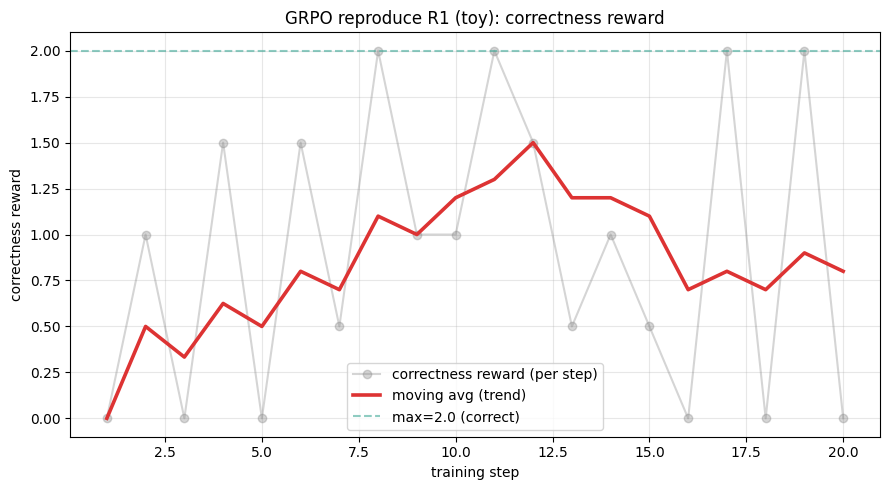

正确性 reward: 前半 0.85 -> 后半 0.95


In [21]:
# ===== 画正确性 reward 曲线:训练到底有没有让模型变强?=====
# %matplotlib inline 是 Jupyter 魔法命令:让图直接显示在 notebook 里
# (原来这里是 matplotlib.use("Agg") = "无窗口后端",图只存文件、不在 notebook 显示 -> 已换掉)
%matplotlib inline
import matplotlib.pyplot as plt  # matplotlib:Python 最常用的画图库

# trainer.state.log_history = 训练全程的日志(字典的列表,每步一条)
# 只保留含 "reward" 键的条目(即训练指标,过滤掉别的杂项日志)
logs = [l for l in trainer.state.log_history if "reward" in l]
steps = [l["step"] for l in logs]                                    # x 轴:第几步
corr  = [l.get("rewards/correctness_reward/mean", 0) for l in logs]  # y 轴:每步正确性分的均值

# 移动平均:每个点取"最近 5 步的平均",把剧烈震荡的原始曲线抹平滑,方便看趋势
def mavg(x, w=5): return [sum(x[max(0,i-w+1):i+1])/len(x[max(0,i-w+1):i+1]) for i in range(len(x))]

plt.figure(figsize=(9,5))                                  # 新建 9x5 英寸的画布
plt.plot(steps, corr, "o-", alpha=0.35, color="#888",      # 灰色半透明圆点线:每步原始值(很跳)
         label="correctness reward (per step)")
plt.plot(steps, mavg(corr), "-", lw=2.6, color="#d33",     # 红色粗线:移动平均(看趋势主要看这条)
         label="moving avg (trend)")
plt.axhline(2.0, ls="--", c="#4a9", alpha=0.6, label="max=2.0 (correct)")  # 绿色虚线:满分参考线
plt.xlabel("training step"); plt.ylabel("correctness reward")              # 坐标轴标签
plt.title("GRPO reproduce R1 (toy): correctness reward")                   # 图标题
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()      # 图例 / 浅网格 / 自动排版防裁切
plt.savefig("reward_curve_notebook.png", dpi=120)          # 存 png(不覆盖正式跑 40 步的 reward_curve.png!)
plt.show()                                                 # 在 notebook 里显示

# 前半段 vs 后半段的平均分:一句话量化"有没有学到"(后半明显高于前半 = 学到了)
half = len(corr)//2 or 1
print(f"正确性 reward: 前半 {sum(corr[:half])/half:.2f} -> 后半 {sum(corr[half:])/max(1,len(corr)-half):.2f}")

## 7. 踩坑总结 & 面试知识点对照 ⭐

### 踩过的坑(面试最值钱)
1. **reward 恒为 0,学不动**:组内得分全一样 → advantage=0 → 无梯度(`frac_reward_zero_std=1`)。排查发现模型**算对了但不按格式**,而正确性裁判只从标签抠 → 答对也判 0。改成兜底取全文数字 + 渐进格式分,才有信号。→ 亲历 **reward 信号塌缩**。
2. **格式学不会**:0.5B 纯 RL 短训学不出 XML 格式。→ 正是 **DeepSeek-R1-Zero 的已知问题**,所以正式 R1 先用**冷启动 SFT** 教格式再上 RL。

### 概念对照(被追问时这样答)
| 问点 | 用本项目回答 |
|---|---|
| reward 设计 | 格式分+正确性分;数值大小=信号权重;广告 CTR/CVR 同理 |
| GRPO vs PPO | GRPO 用**组内平均当 baseline**算 advantage,**省掉 PPO 的 value 网络** |
| 组内 advantage | 同题 4 个回答,reward 减组内均值,高于均值的被鼓励 |
| reward hacking | 若正确性只看"含正确数字",模型会把一堆数字全列出来骗分;广告里=标题党刷 CTR |
| on-policy | 每步用模型**当下生成**的回答训自己 |
| KL/beta | beta=0.04 防模型为刷分跑离原模型太远 |
| 为何要冷启动 SFT | 见坑2:纯 RL 格式学不好 |

> **定位**:这是理解 RL 机制的**最小雏形**,非生产级。被问规模/效果如实说"小模型、短训练、正确率有升、格式没学会"——真实理解比夸大值钱。